In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [2]:
df = pd.read_csv("Cleaned.csv")

print(f"Shape" , df.shape)
df.head()

Shape (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [5]:
print("Total Columns:", len(df.columns))

print("\nAll Dataset Columns:")
print(df.columns.tolist())

Total Columns: 21

All Dataset Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:

df = df.drop(columns=["customerID"])

print("customerID removed successfully!")

print("New Dataset Shape:", df.shape)


customerID removed successfully!
New Dataset Shape: (7043, 20)


In [7]:
X = df.drop(columns=["Churn"])

y = df["Churn"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (7043, 19)
Target Variable Shape: (7043,)


In [8]:
print("shape" , df.shape)
print(X.shape)
print(y.shape)

shape (7043, 20)
(7043, 19)
(7043,)


In [9]:
print('target variable')
print(y.value_counts())

target variable
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import LabelEncoder

In [11]:
le = LabelEncoder()
y = le.fit_transform(y)

In [12]:
print('Encoded Target Values : ')
print(pd.Series(y).value_counts())

Encoded Target Values : 
0    5174
1    1869
Name: count, dtype: int64


In [13]:
print(le.classes_)

['No' 'Yes']


In [14]:
print("Target Shape:", y.shape)
print("Unique Values:", np.unique(y))

Target Shape: (7043,)
Unique Values: [0 1]


In [15]:
categorical_cols = X.select_dtypes(
    include=["object", "str", "string"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nTotal Categorical Columns:", len(categorical_cols))

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Categorical Columns: 15


In [16]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)


Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [17]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

print("One-Hot Encoder created successfully!")

One-Hot Encoder created successfully!


In [18]:
print("Numerical Columns:")
print(numerical_cols)

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

print("StandardScaler created successfully!")

StandardScaler created successfully!


In [20]:
sample_data = pd.DataFrame({
    "MonthlyCharges": [20, 50, 80, 100]
})

sample_scaler = StandardScaler()

scaled_data = sample_scaler.fit_transform(sample_data)

print("Original Data:")
print(sample_data)

print("\nScaled Data:")
print(scaled_data)

Original Data:
   MonthlyCharges
0              20
1              50
2              80
3             100

Scaled Data:
[[-1.40213637]
 [-0.41239305]
 [ 0.57735027]
 [ 1.23717915]]


In [21]:
# Input features
X = df.drop(columns=["Churn"])

# Target variable
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Input Features (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

Input Features (X):
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1           

In [22]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7043, 19)
y Shape: (7043,)


In [23]:
print("Missing Values in X:")
print(X.isnull().sum().sum())

print("\nMissing Values in y:")
print(y.isnull().sum())

Missing Values in X:
0

Missing Values in y:
0


In [24]:
print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [27]:
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (5634, 19)
X_test Shape: (1409, 19)
y_train Shape: (5634,)
y_test Shape: (1409,)


In [28]:
print("Training Data Churn Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Data Churn Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Data Churn Distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing Data Churn Distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [29]:
print("Target Variable Distribution:")
print(y.value_counts())

Target Variable Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [30]:
class_percentage = y.value_counts(normalize=True) * 100

print("Class Percentage:")
print(class_percentage.round(2))

Class Percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


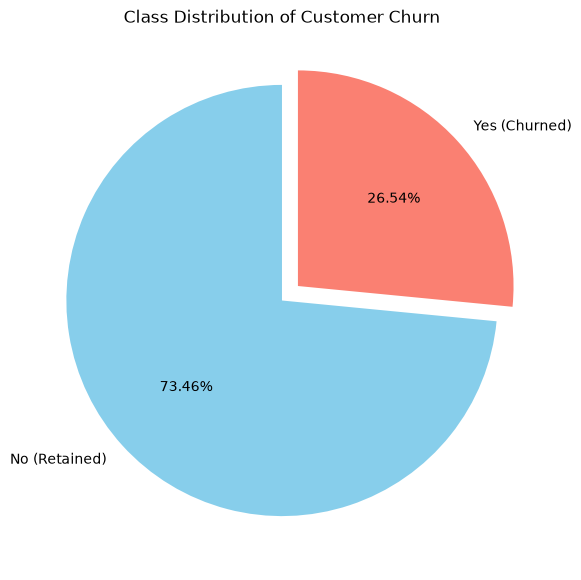

In [31]:
plt.figure(figsize=(7, 7))

class_counts = y.value_counts().sort_index()

plt.pie(
    class_counts,
    labels=["No (Retained)", "Yes (Churned)"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["skyblue", "salmon"],
    explode=(0, 0.1)
)

plt.title("Class Distribution of Customer Churn")

plt.show()

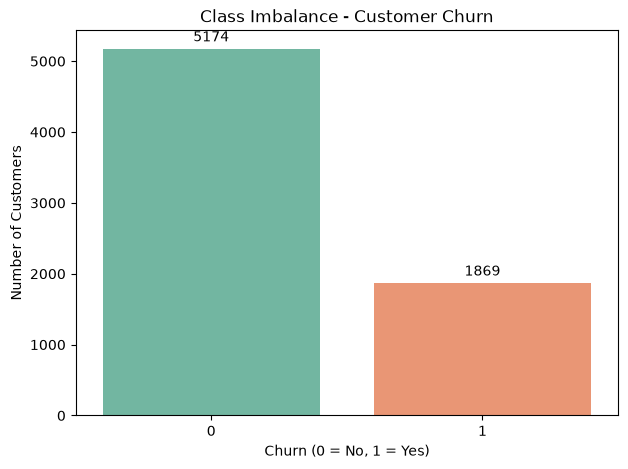

In [32]:
import seaborn as sns
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Class Imbalance - Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

In [33]:
print("Training Data Distribution:")
print(y_train.value_counts())

print("\nTesting Data Distribution:")
print(y_test.value_counts())

Training Data Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Data Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [34]:
print("Training Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Percentage:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing Percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [35]:
categorical_cols = X.select_dtypes(
    include=["object", "str", "string"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# SeniorCitizen is binary, so exclude it from scaling
scaling_cols = [
    col for col in numerical_cols
    if col != "SeniorCitizen"
]

print("Categorical Columns:", categorical_cols)
print("\nNumerical Columns:", numerical_cols)
print("\nColumns to Scale:", scaling_cols)

Categorical Columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Columns to Scale: ['tenure', 'MonthlyCharges', 'TotalCharges']


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [37]:
# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, scaling_cols),
        ("cat", categorical_transformer, categorical_cols)
    ],
    remainder="passthrough"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [39]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Training data preprocessing completed!")
print("Shape:", X_train_processed.shape)

Training data preprocessing completed!
Shape: (5634, 30)


In [40]:
X_test_processed = preprocessor.transform(X_test)

print("Testing data preprocessing completed!")
print("Shape:", X_test_processed.shape)

Testing data preprocessing completed!
Shape: (1409, 30)


In [41]:
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Original Training Shape: (5634, 19)
Processed Training Shape: (5634, 30)

Original Testing Shape: (1409, 19)
Processed Testing Shape: (1409, 30)


In [42]:
print("Missing values in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing data:",
      np.isnan(X_test_processed).sum())

Missing values in training data: 0
Missing values in testing data: 0


In [43]:
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

print("Final Training Data:")
display(X_train_processed.head())

print("\nFinal Testing Data:")
display(X_test_processed.head())

Final Training Data:


,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Male,cat__Partner_Yes,cat__Dependents_Yes,cat__PhoneService_Yes,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,cat__InternetService_Fiber optic,...,cat__StreamingTV_Yes,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_Yes,cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,remainder__SeniorCitizen
0,0.102371,-0.521976,-0.262257,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.711743,0.337478,-0.503635,1.0,1.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.793155,-0.809013,-0.749883,1.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,-0.263980,0.284384,-0.172722,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
4,-1.281624,-0.676279,-0.989374,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0



Final Testing Data:


,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Male,cat__Partner_Yes,cat__Dependents_Yes,cat__PhoneService_Yes,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,cat__InternetService_Fiber optic,...,cat__StreamingTV_Yes,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_Yes,cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,remainder__SeniorCitizen
0,1.608483,1.629976,2.706828,1.0,1.0,1.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
1,-0.996684,1.168725,-0.610260,0.0,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,0.346606,0.445324,0.400116,0.0,1.0,1.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
3,-0.589626,0.440347,-0.364451,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.608483,0.588013,1.588421,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0


In [44]:
print("Final Training Shape:", X_train_processed.shape)
print("Final Testing Shape:", X_test_processed.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Data Types:")
print(X_train_processed.dtypes.value_counts())

Final Training Shape: (5634, 30)
Final Testing Shape: (1409, 30)

Training Target Shape: (5634,)
Testing Target Shape: (1409,)

Training Data Types:
float64    30
Name: count, dtype: int64


Machine Learning

In [45]:
# Import Machine Learning Algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import Model Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Import Model Saving Library

import joblib

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [46]:
print("Training Features:", X_train_processed.shape)
print("Testing Features:", X_test_processed.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 30)
Testing Features: (1409, 30)
Training Target: (5634,)
Testing Target: (1409,)


In [47]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [48]:
log_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [49]:
y_pred_log = log_model.predict(X_test_processed)

print("Predictions generated successfully!")

print(y_pred_log[:10])

Predictions generated successfully!
[0 1 0 0 0 1 0 0 0 0]


In [50]:
y_prob_log = log_model.predict_proba(X_test_processed)[:, 1]

print("Churn Probabilities:")
print(y_prob_log[:10])

Churn Probabilities:
[0.0464133  0.68419325 0.0603014  0.39859274 0.02183171 0.60351226
 0.44587604 0.12874292 0.00290068 0.39573055]


In [51]:
log_accuracy = accuracy_score(
    y_test,
    y_pred_log
)

print("Logistic Regression Accuracy:",
      round(log_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.62 %


In [52]:
log_accuracy = accuracy_score(
    y_test,
    y_pred_log
)

print("Logistic Regression Accuracy:",
      round(log_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.62 %


In [53]:
print(
    classification_report(
        y_test,
        y_pred_log,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



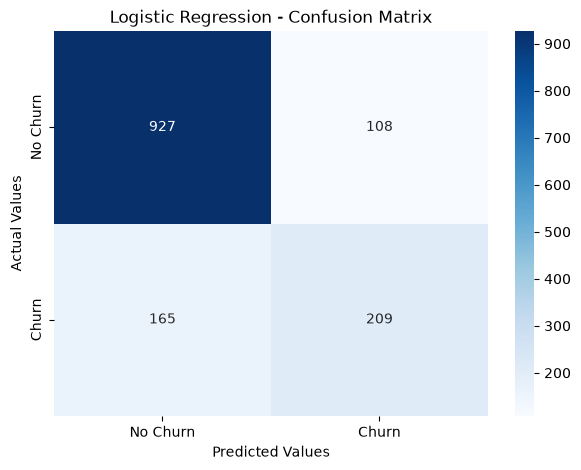

In [54]:
cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [55]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [56]:
dt_model.fit(
    X_train_processed,
    y_train
)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [57]:
y_pred_dt = dt_model.predict(X_test_processed)

print("Decision Tree Predictions:")
print(y_pred_dt[:10])

Decision Tree Predictions:
[0 1 0 0 0 0 0 0 0 0]


In [58]:
y_prob_dt = dt_model.predict_proba(X_test_processed)[:, 1]

print("Churn Probabilities:")
print(y_prob_dt[:10])

Churn Probabilities:
[0.         0.75087719 0.1027668  0.33793103 0.00981595 0.3220339
 0.3220339  0.03010033 0.00981595 0.03010033]


In [59]:
dt_accuracy = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    round(dt_accuracy * 100, 2),
    "%"
)


Decision Tree Accuracy: 79.42 %


In [60]:
print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



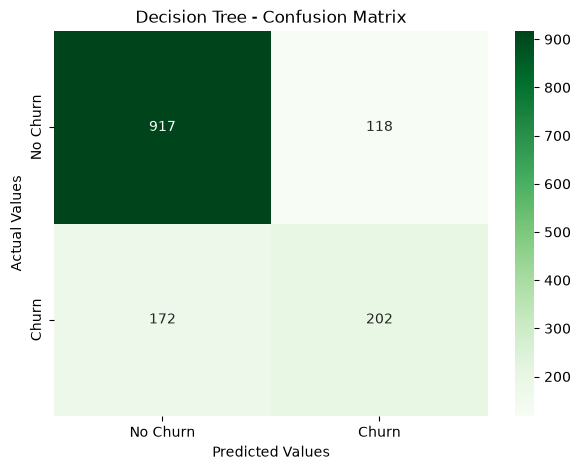

In [61]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [62]:
print("Logistic Regression Accuracy:",
      round(log_accuracy * 100, 2), "%")

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.62 %
Decision Tree Accuracy: 79.42 %


In [63]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [64]:
rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [65]:
y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest Predictions:")
print(y_pred_rf[:10])

Random Forest Predictions:
[0 1 0 0 0 1 0 0 0 0]


In [66]:
y_prob_rf = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Churn Probabilities:")
print(y_prob_rf[:10])

Churn Probabilities:
[0.01134321 0.76400856 0.10426874 0.33826444 0.00996129 0.52247983
 0.38790548 0.07608801 0.01143875 0.39880961]


In [67]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    round(rf_accuracy * 100, 2),
    "%"
)

Random Forest Accuracy: 80.2 %


In [68]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



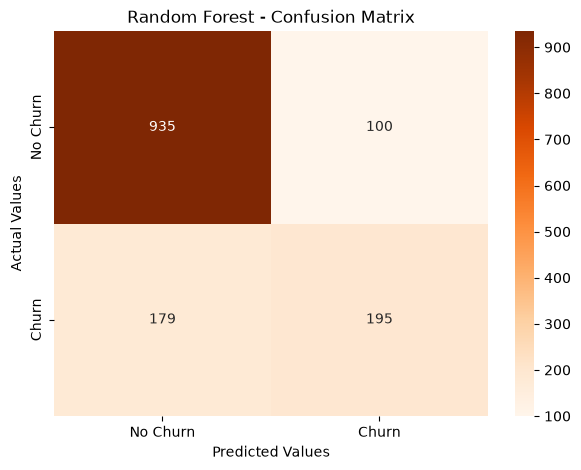

In [69]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [70]:
print("Logistic Regression:",
      round(log_accuracy * 100, 2), "%")

print("Decision Tree:",
      round(dt_accuracy * 100, 2), "%")

print("Random Forest:",
      round(rf_accuracy * 100, 2), "%")

Logistic Regression: 80.62 %
Decision Tree: 79.42 %
Random Forest: 80.2 %


In [71]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Churn probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

print("Model comparison completed!")

Model comparison completed!


In [72]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

comparison_df = comparison_df.round(4)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8062,0.6593,0.5588,0.6049,0.8422
2,Random Forest,0.8020,0.6610,0.5214,0.5830,0.8386
1,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267


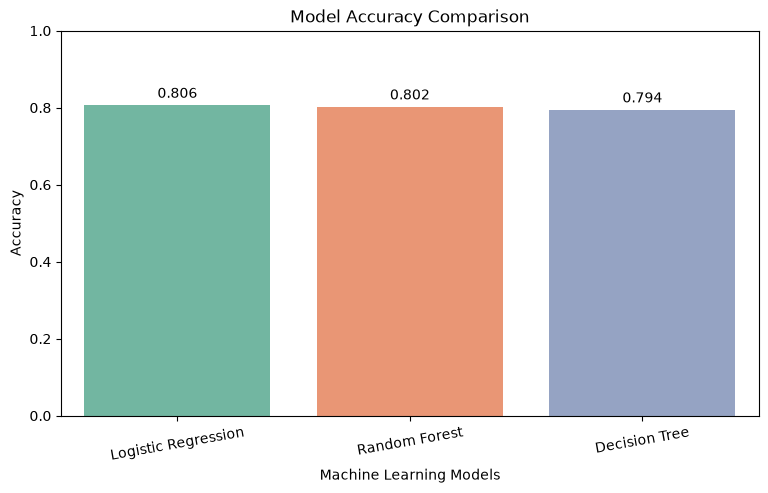

In [73]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=10)

plt.show()

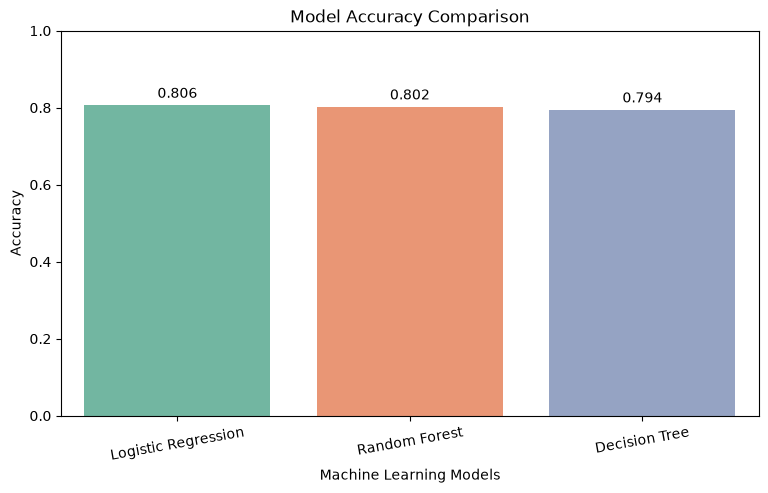

In [74]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=10)

plt.show()

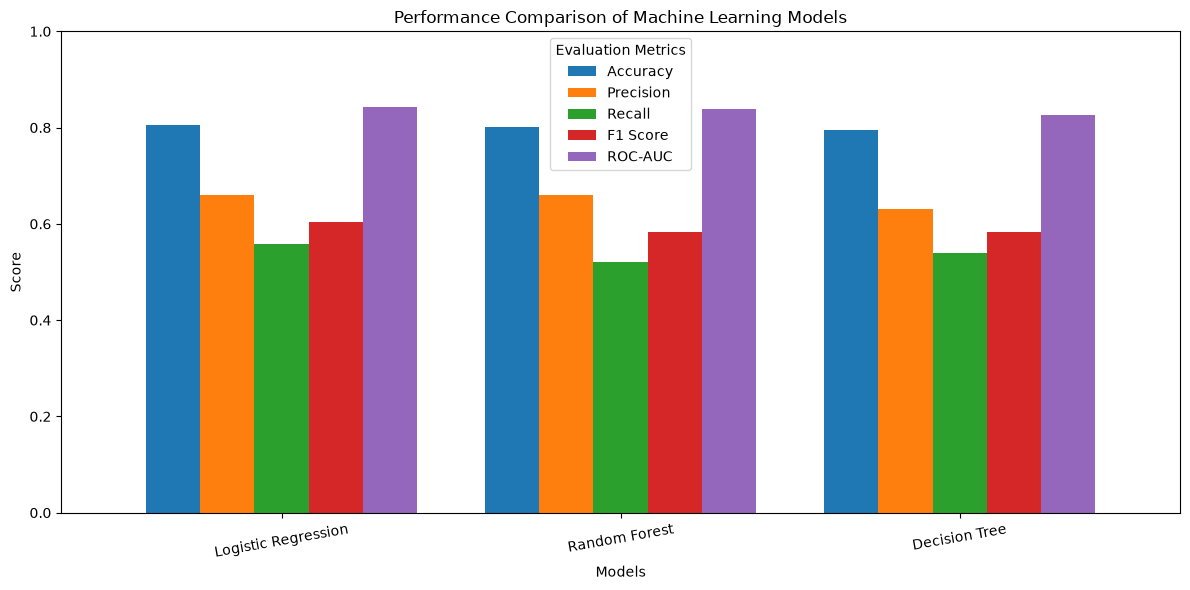

In [75]:
metrics_df = comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]

metrics_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.legend(title="Evaluation Metrics")

plt.tight_layout()
plt.show()

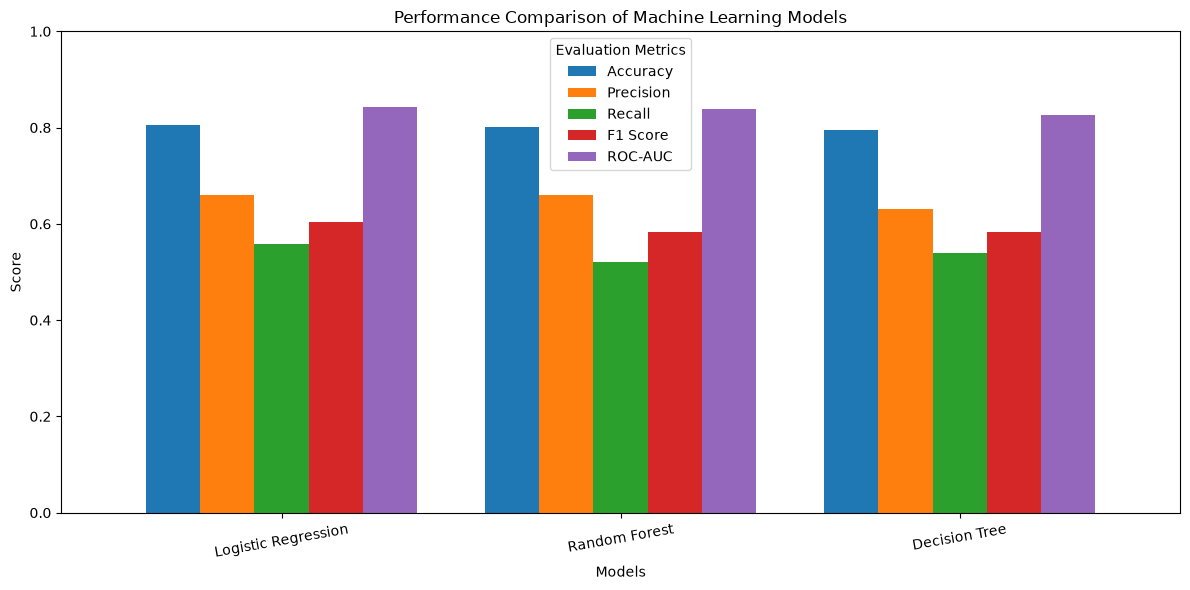

In [76]:
metrics_df = comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]

metrics_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.legend(title="Evaluation Metrics")

plt.tight_layout()
plt.show()

In [77]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print(
    "Best F1 Score:",
    comparison_df.iloc[0]["F1 Score"]
)

Best Model: Logistic Regression
Best F1 Score: 0.6049


In [78]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

print("All models evaluated successfully!")

All models evaluated successfully!


In [79]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

comparison_df = comparison_df.round(4)

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8062,0.6593,0.5588,0.6049,0.8422
2,Random Forest,0.8020,0.6610,0.5214,0.5830,0.8386
1,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267


In [80]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("F1 Score:", comparison_df.iloc[0]["F1 Score"])

Best Model: Logistic Regression
F1 Score: 0.6049


In [81]:
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [82]:
# Logistic Regression ROC
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
auc_log = roc_auc_score(y_test, y_prob_log)

# Decision Tree ROC
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Logistic Regression AUC:", round(auc_log, 4))
print("Decision Tree AUC:", round(auc_dt, 4))
print("Random Forest AUC:", round(auc_rf, 4))

Logistic Regression AUC: 0.8422
Decision Tree AUC: 0.8267
Random Forest AUC: 0.8386


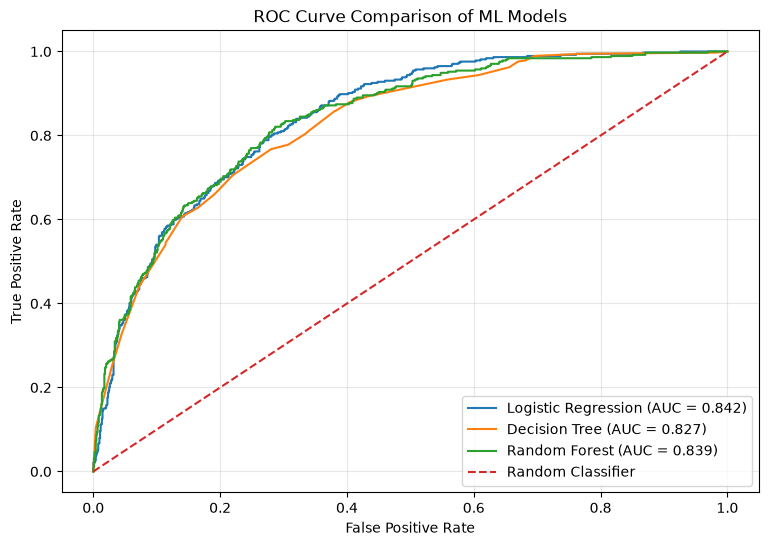

In [83]:
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.3f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {auc_dt:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison of ML Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

In [84]:
auc_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "AUC Score": [
        auc_log,
        auc_dt,
        auc_rf
    ]
})

auc_comparison = auc_comparison.sort_values(
    by="AUC Score",
    ascending=False
)

display(auc_comparison.round(4))

,Model,AUC Score
0,Logistic Regression,0.8422
2,Random Forest,0.8386
1,Decision Tree,0.8267


In [85]:
best_auc_model = auc_comparison.iloc[0]["Model"]
best_auc_score = auc_comparison.iloc[0]["AUC Score"]

print("Best AUC Model:", best_auc_model)
print("Best AUC Score:", round(best_auc_score, 4))

Best AUC Model: Logistic Regression
Best AUC Score: 0.8422


In [86]:
# Extract feature importance
feature_importance = rf_model.feature_importances_

# Get feature names
feature_names = X_train_processed.columns

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
0,num__tenure,0.187088
2,num__TotalCharges,0.169820
1,num__MonthlyCharges,0.122502
9,cat__InternetService_Fiber optic,0.071014
27,cat__PaymentMethod_Electronic check,0.062687
24,cat__Contract_Two year,0.048066
12,cat__OnlineSecurity_Yes,0.032392
23,cat__Contract_One year,0.026528
18,cat__TechSupport_Yes,0.026464
25,cat__PaperlessBilling_Yes,0.023415


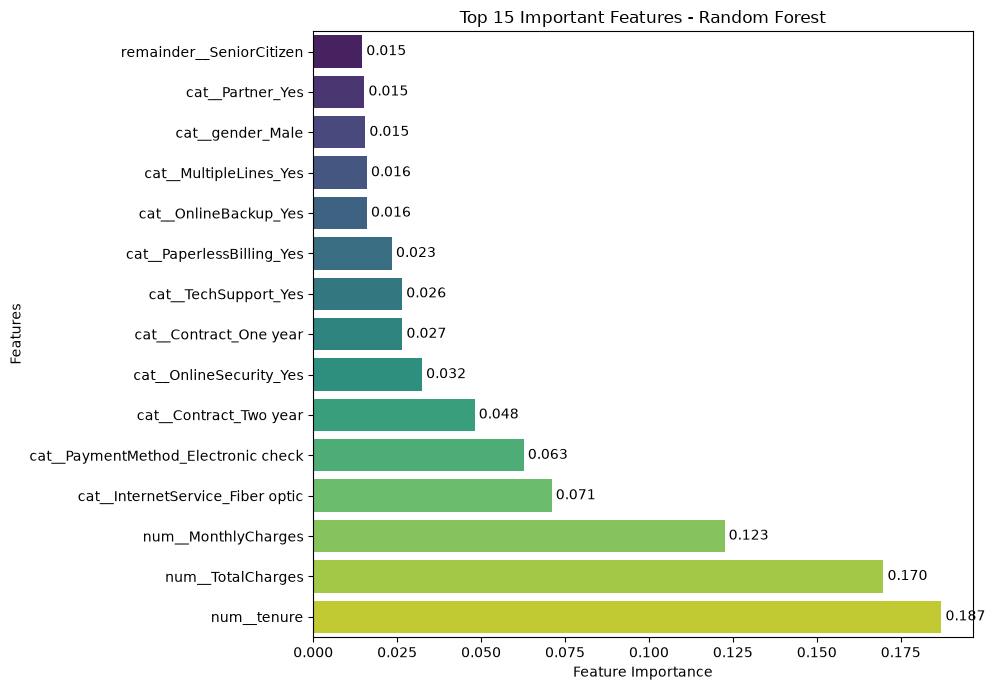

In [87]:
plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

ax = sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [88]:
most_important = importance_df.iloc[0]

print("Most Important Feature:", most_important["Feature"])
print("Importance Score:", round(most_important["Importance"], 4))

Most Important Feature: num__tenure
Importance Score: 0.1871


In [89]:
importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [90]:
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8062,0.6593,0.5588,0.6049,0.8422
2,Random Forest,0.8020,0.6610,0.5214,0.5830,0.8386
1,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267


In [91]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("Best F1 Score:", comparison_df.iloc[0]["F1 Score"])

Best Model: Logistic Regression
Best F1 Score: 0.6049


In [92]:
if best_model_name == "Logistic Regression":
    best_model = log_model

elif best_model_name == "Decision Tree":
    best_model = dt_model

elif best_model_name == "Random Forest":
    best_model = rf_model

print("Best model selected successfully!")

Best model selected successfully!


In [93]:
y_pred_best = best_model.predict(X_test_processed)
y_prob_best = best_model.predict_proba(X_test_processed)[:, 1]

print("Best Model:", best_model_name)
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Best Model: Logistic Regression
Accuracy: 0.8062455642299503
Precision: 0.6593059936908517
Recall: 0.5588235294117647
F1 Score: 0.6049204052098408
ROC-AUC: 0.8421710713270816

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [94]:
import joblib
import os

In [95]:
os.makedirs("Models", exist_ok=True)

In [96]:
joblib.dump(best_model, "Models/best_churn_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [97]:
joblib.dump(preprocessor, "Models/churn_preprocessor.pkl")

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [98]:
print(os.listdir("Models"))

['best_churn_model.pkl', 'churn_preprocessor.pkl']


In [99]:
loaded_model = joblib.load("Models/best_churn_model.pkl")
loaded_preprocessor = joblib.load("Models/churn_preprocessor.pkl")

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")

Model loaded successfully!
Preprocessor loaded successfully!


In [100]:
new_customer = pd.DataFrame({
    "gender": ["Male"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [85.50],
    "TotalCharges": [427.50]
})

display(new_customer)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Male,0,Yes,No,5,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,85.5,427.5


In [101]:
new_customer_processed = loaded_preprocessor.transform(new_customer)

print("Original data shape:", new_customer.shape)
print("Processed data shape:", new_customer_processed.shape)

Original data shape: (1, 19)
Processed data shape: (1, 30)


In [102]:
prediction = loaded_model.predict(new_customer_processed)

if prediction[0] == 1:
    print("Prediction: Customer is likely to Churn")
else:
    print("Prediction: Customer is likely to Stay")

Prediction: Customer is likely to Churn


C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [103]:
churn_probability = loaded_model.predict_proba(
    new_customer_processed
)[0][1]

stay_probability = loaded_model.predict_proba(
    new_customer_processed
)[0][0]

print("Stay Probability:", round(stay_probability * 100, 2), "%")
print("Churn Probability:", round(churn_probability * 100, 2), "%")

Stay Probability: 21.62 %
Churn Probability: 78.38 %


C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [104]:
if prediction[0] == 1:
    result = "Customer is likely to Churn"
else:
    result = "Customer is likely to Stay"

print("Customer Churn Prediction Report")
print("--------------------------------")
print("Prediction:", result)
print("Churn Probability:", round(churn_probability * 100, 2), "%")
print("Stay Probability:", round(stay_probability * 100, 2), "%")

Customer Churn Prediction Report
--------------------------------
Prediction: Customer is likely to Churn
Churn Probability: 78.38 %
Stay Probability: 21.62 %


In [105]:
multiple_customers = X_test.head(10).copy()

display(multiple_customers)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,No,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),19.75,1311.60
1639,Male,1,No,No,17,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,45.05,770.60


In [106]:
multiple_customers_processed = loaded_preprocessor.transform(
    multiple_customers
)

print("Processed Shape:", multiple_customers_processed.shape)

Processed Shape: (10, 30)


In [107]:
multiple_predictions = loaded_model.predict(
    multiple_customers_processed
)

multiple_probabilities = loaded_model.predict_proba(
    multiple_customers_processed
)[:, 1]

C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [108]:
prediction_report = multiple_customers.copy()

prediction_report["Predicted_Churn"] = multiple_predictions

prediction_report["Churn_Probability"] = (
    multiple_probabilities * 100
).round(2)

prediction_report["Predicted_Churn"] = (
    prediction_report["Predicted_Churn"]
    .map({0: "No", 1: "Yes"})
)

display(prediction_report)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Predicted_Churn,Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,No,4.64
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,Yes,68.42
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,No,6.03
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,No,39.86
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,No,2.18
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,Yes,60.35
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,...,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,No,44.59
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,No,12.87
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),19.75,1311.60,No,0.29
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,No,39.57


In [109]:
prediction_report["Actual_Churn"] = (
    y_test.loc[multiple_customers.index]
    .map({0: "No", 1: "Yes"})
)

display(
    prediction_report[
        ["Predicted_Churn", "Churn_Probability", "Actual_Churn"]
    ]
)

,Predicted_Churn,Churn_Probability,Actual_Churn
437,No,4.64,No
2280,Yes,68.42,No
2235,No,6.03,No
4460,No,39.86,No
3761,No,2.18,No
5748,Yes,60.35,No
3568,No,44.59,No
2976,No,12.87,No
5928,No,0.29,No
1639,No,39.57,Yes


In [110]:
def risk_category(probability):
    if probability >= 70:
        return "High Risk"
    elif probability >= 40:
        return "Medium Risk"
    else:
        return "Low Risk"

prediction_report["Risk_Category"] = (
    prediction_report["Churn_Probability"]
    .apply(risk_category)
)

display(prediction_report)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Predicted_Churn,Churn_Probability,Actual_Churn,Risk_Category
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,No,4.64,No,Low Risk
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,Yes,68.42,No,Medium Risk
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,One year,Yes,Credit card (automatic),78.35,3211.20,No,6.03,No,Low Risk
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,Month-to-month,No,Electronic check,78.20,1468.75,No,39.86,No,Low Risk
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,No,2.18,No,Low Risk
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,Yes,60.35,No,Medium Risk
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,No,44.59,No,Medium Risk
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,...,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,No,12.87,No,Low Risk
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,...,No internet service,Two year,No,Credit card (automatic),19.75,1311.60,No,0.29,No,Low Risk
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,Month-to-month,Yes,Electronic check,45.05,770.60,No,39.57,Yes,Low Risk


In [111]:
prediction_report.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Prediction dataset saved successfully!")

Prediction dataset saved successfully!


In [112]:
y_pred_final = best_model.predict(X_test_processed)

y_prob_final = best_model.predict_proba(
    X_test_processed
)[:, 1]

In [113]:
cm = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[927 108]
 [165 209]]


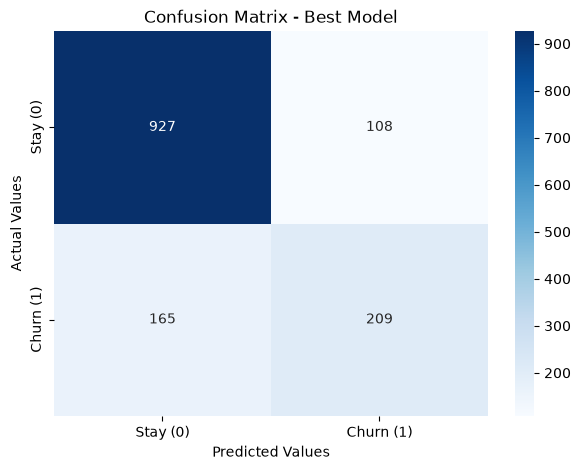

In [114]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay (0)", "Churn (1)"],
    yticklabels=["Stay (0)", "Churn (1)"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix - Best Model")

plt.show()

In [115]:
final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)
final_auc = roc_auc_score(y_test, y_prob_final)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("Model:", best_model_name)
print("Accuracy:", round(final_accuracy * 100, 2), "%")
print("Precision:", round(final_precision * 100, 2), "%")
print("Recall:", round(final_recall * 100, 2), "%")
print("F1 Score:", round(final_f1 * 100, 2), "%")
print("ROC-AUC:", round(final_auc, 4))

FINAL MODEL PERFORMANCE
-----------------------
Model: Logistic Regression
Accuracy: 80.62 %
Precision: 65.93 %
Recall: 55.88 %
F1 Score: 60.49 %
ROC-AUC: 0.8422


In [116]:
error_analysis = pd.DataFrame({
    "Actual_Churn": y_test,
    "Predicted_Churn": y_pred_final,
    "Churn_Probability": (y_prob_final * 100).round(2)
})

error_analysis["Prediction_Status"] = np.where(
    error_analysis["Actual_Churn"] == error_analysis["Predicted_Churn"],
    "Correct",
    "Incorrect"
)

display(error_analysis.head(20))

,Actual_Churn,Predicted_Churn,Churn_Probability,Prediction_Status
437,0,0,4.64,Correct
2280,0,1,68.42,Incorrect
2235,0,0,6.03,Correct
4460,0,0,39.86,Correct
3761,0,0,2.18,Correct
5748,0,1,60.35,Incorrect
3568,0,0,44.59,Correct
2976,0,0,12.87,Correct
5928,0,0,0.29,Correct
1639,1,0,39.57,Incorrect


In [117]:
print(
    error_analysis["Prediction_Status"].value_counts()
)

Prediction_Status
Correct      1136
Incorrect     273
Name: count, dtype: int64


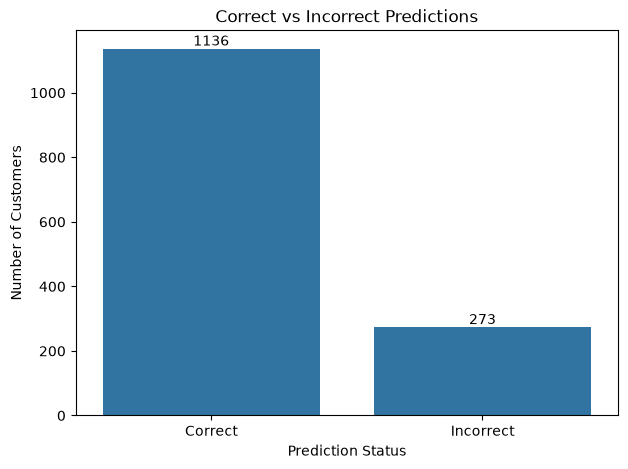

In [118]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=error_analysis,
    x="Prediction_Status"
)

ax.bar_label(ax.containers[0])

plt.title("Correct vs Incorrect Predictions")
plt.xlabel("Prediction Status")
plt.ylabel("Number of Customers")

plt.show()

In [119]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_auc
    ]
})

final_metrics.to_csv(
    "final_model_evaluation.csv",
    index=False
)

print("Final evaluation report saved successfully!")

Final evaluation report saved successfully!


In [121]:
full_data = pd.read_csv("Cleaned.csv")

print("Dataset Shape:", full_data.shape)

Dataset Shape: (7043, 21)


In [122]:
full_X = full_data.drop(
    columns=["customerID", "Churn"]
)

full_X_processed = loaded_preprocessor.transform(full_X)

full_predictions = loaded_model.predict(full_X_processed)

full_probabilities = loaded_model.predict_proba(
    full_X_processed
)[:, 1]

C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [123]:
full_prediction_report = full_data.copy()

full_prediction_report["Predicted_Churn"] = (
    pd.Series(full_predictions)
    .map({0: "No", 1: "Yes"})
)

full_prediction_report["Churn_Probability"] = (
    full_probabilities * 100
).round(2)

full_prediction_report["Risk_Category"] = (
    full_prediction_report["Churn_Probability"]
    .apply(risk_category)
)

In [124]:
full_prediction_report.to_csv(
    "customer_churn_predictions_full.csv",
    index=False
)

print("Total Customers:", len(full_prediction_report))
print("Total Columns:", len(full_prediction_report.columns))

display(full_prediction_report.head())

Total Customers: 7043
Total Columns: 24


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Predicted_Churn,Churn_Probability,Risk_Category
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Yes,61.53,Medium Risk
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,One year,No,Mailed check,56.95,1889.50,No,No,4.52,Low Risk
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,No,29.98,Low Risk
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,No,2.85,Low Risk
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Yes,69.34,Medium Risk
